In [9]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/2026task1/submission-for-task2.csv
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/lzxpeiohkd.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/xonkpltokc.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/egpzdxqvpd.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/xwgxsdrayz.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/rojhnoqhlm.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/skvswklmwr.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/kmdvdjjrja.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/esqiikafkg.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/urwemzusdg.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/ulzmjrmejy.png
/kaggle/

/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 21106 (\N{CJK UNIFIED IDEOGRAPH-5272}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:52: UserWarning: Glyph 32511 (\N{CJK UNIFIED IDEOGRAPH-7EFF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1

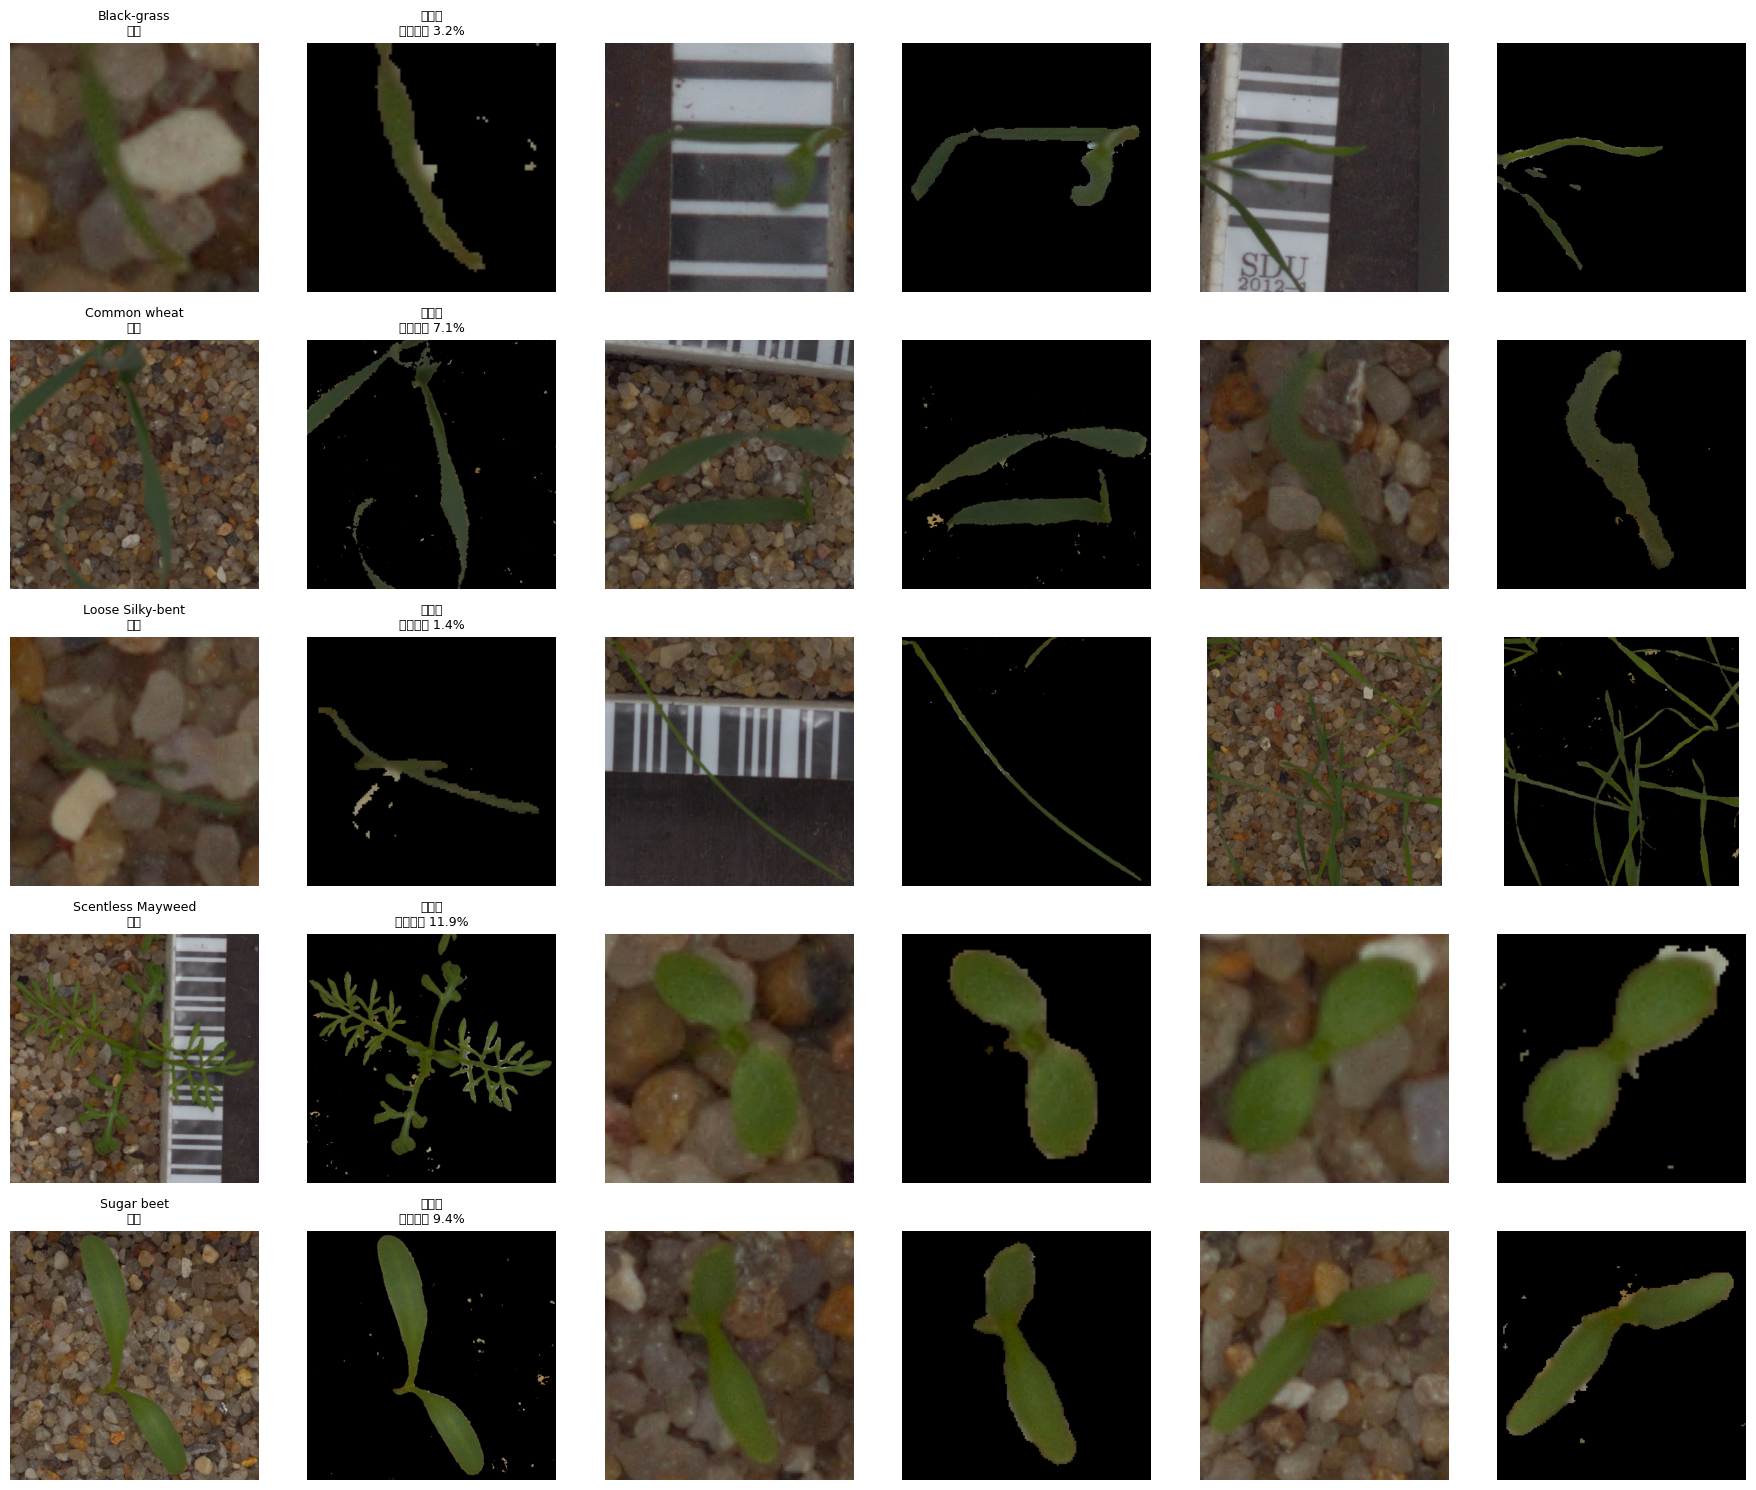

/tmp/ipykernel_19988/2714735369.py:69: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/2714735369.py:69: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()


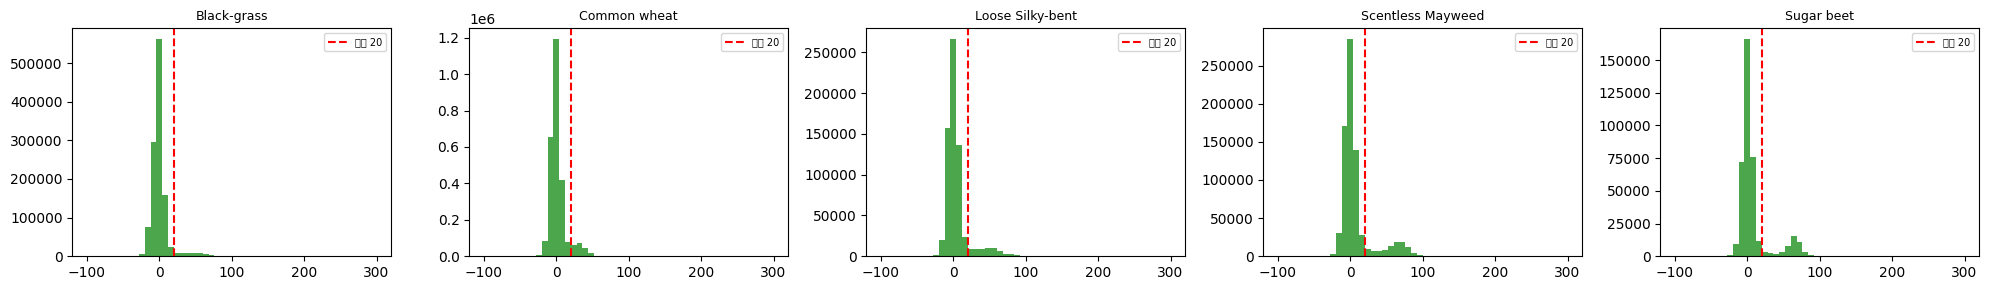

In [24]:
import os, random, numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import seaborn as sns
from tqdm.auto import tqdm
import timm

# ============ 绿色阈值分割（只返回 image） ============
def green_segment(img_pil, exg_threshold=17, ratio_threshold=0.8):
    """ExG = 2G - R - B，非绿色区域填黑"""
    arr = np.array(img_pil.convert('RGB')).astype(np.int16)
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    exg = 2 * g - r - b
    mask = (exg > exg_threshold) & (g > r * ratio_threshold) & (g > b * ratio_threshold)
    out = np.zeros_like(arr, dtype=np.uint8)
    out[mask] = arr[mask].astype(np.uint8)
    return Image.fromarray(out)


def green_mask(img_pil, exg_threshold=10, ratio_threshold=1.05):
    """只返回 mask，用于可视化"""
    arr = np.array(img_pil.convert('RGB')).astype(np.int16)
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    exg = 2 * g - r - b
    return (exg > exg_threshold) & (g > r * ratio_threshold) & (g > b * ratio_threshold)


# ============ 可视化验证 ============
DATA_ROOT = "/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
classes = sorted([c for c in os.listdir(TRAIN_DIR)
                  if os.path.isdir(os.path.join(TRAIN_DIR, c))])

fig, axes = plt.subplots(len(classes), 6, figsize=(18, 3*len(classes)))
for i, c in enumerate(classes):
    d = os.path.join(TRAIN_DIR, c)
    files = os.listdir(d)[:3]
    for j, f in enumerate(files):
        img = Image.open(os.path.join(d, f)).convert('RGB')
        seg = green_segment(img)
        mask = green_mask(img)
        axes[i, 2*j].imshow(img); axes[i, 2*j].axis('off')
        axes[i, 2*j+1].imshow(seg); axes[i, 2*j+1].axis('off')
        if j == 0:
            axes[i, 0].set_title(f"{c}\n原图", fontsize=9)
            axes[i, 1].set_title(f"分割后\n绿色占比 {mask.mean()*100:.1f}%", fontsize=9)
plt.tight_layout(); plt.show()

# ============ ExG 分布直方图 ============
fig, axes = plt.subplots(1, len(classes), figsize=(4*len(classes), 3))
if len(classes) == 1: axes = [axes]
for ax, c in zip(axes, classes):
    d = os.path.join(TRAIN_DIR, c)
    files = os.listdir(d)[:5]
    all_exg = []
    for f in files:
        arr = np.array(Image.open(os.path.join(d, f)).convert('RGB')).astype(np.int16)
        r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
        all_exg.append((2*g - r - b).ravel())
    all_exg = np.concatenate(all_exg)
    ax.hist(all_exg, bins=50, range=(-100, 300), color='green', alpha=0.7)
    ax.axvline(20, color='red', linestyle='--', label='阈值 20')
    ax.set_title(c, fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [16]:
DATA_ROOT = "/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
TEST_DIR  = os.path.join(DATA_ROOT, "test")

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.15)),
])
val_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE*1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])


class PlantDataset(Dataset):
    """训练/验证集：每次取图时动态做绿色分割"""
    def __init__(self, root, transform=None, samples=None, use_segment=True):
        self.transform = transform
        self.use_segment = use_segment
        if samples is None:
            samples = []
            for ci, c in enumerate(sorted([d for d in os.listdir(root)
                                           if os.path.isdir(os.path.join(root, d))])):
                d = os.path.join(root, c)
                for f in os.listdir(d):
                    if f.lower().endswith(('.jpg','.jpeg','.png','.webp')):
                        samples.append((os.path.join(d, f), ci))
        self.samples = samples

    def __len__(self): return len(self.samples)

    def __getitem__(self, i):
        p, y = self.samples[i]
        img = Image.open(p).convert('RGB')
        if self.use_segment:
            img = green_segment(img)     # ← 关键：动态分割
        if self.transform: img = self.transform(img)
        return img, y


class TestDataset(Dataset):
    """测试集：无标签，同样走绿色分割"""
    def __init__(self, root, transform=None, use_segment=True):
        self.paths = sorted([os.path.join(root, f) for f in os.listdir(root)
                             if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))])
        self.transform = transform
        self.use_segment = use_segment

    def __len__(self): return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        if self.use_segment:
            img = green_segment(img)
        if self.transform: img = self.transform(img)
        return img


# 划分训练/验证
full = PlantDataset(TRAIN_DIR)
labels = [y for _, y in full.samples]
idx = list(range(len(full)))
tr_idx, va_idx = train_test_split(idx, test_size=0.2, stratify=labels, random_state=SEED)

train_ds = PlantDataset(TRAIN_DIR, train_tf, [full.samples[i] for i in tr_idx])
val_ds   = PlantDataset(TRAIN_DIR, val_tf,   [full.samples[i] for i in va_idx])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)

NUM_CLASSES = len(set(labels))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"训练 {len(train_ds)} / 验证 {len(val_ds)} / 类别数 {NUM_CLASSES}")
print(f"设备: {DEVICE}")
print(f"TEST_DIR = {TEST_DIR}")
print(f"测试集图片数: {len([f for f in os.listdir(TEST_DIR) if f.lower().endswith(('.png','.jpg','.jpeg'))])}")

训练 400 / 验证 100 / 类别数 5
设备: cuda
TEST_DIR = /kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test
测试集图片数: 378


In [17]:
from timm.data import Mixup

mixup_fn = Mixup(
    mixup_alpha=0.5,
    cutmix_alpha=1.0,
    cutmix_minmax=None,
    prob=1.0,
    switch_prob=0.5,
    mode='batch',
    label_smoothing=0.1,
    num_classes=NUM_CLASSES
)
print("Mixup/CutMix 已启用")

Mixup/CutMix 已启用


In [18]:
class ConvNeXtPlant(nn.Module):
    def __init__(self, num_classes=5, model_name='convnext_tiny',
                 pretrained=True, freeze_backbone=True, drop_path_rate=0.1):
        super().__init__()
        self.backbone = timm.create_model(
            model_name, pretrained=pretrained,
            num_classes=0, drop_path_rate=drop_path_rate
        )
        self.num_features = self.backbone.num_features
        self.fc = nn.Linear(self.num_features, num_classes)
        if freeze_backbone:
            self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False

    def unfreeze_last_stage(self):
        for name, param in self.backbone.named_parameters():
            if 'stages.3' in name or 'norm' in name:
                param.requires_grad = True

    def forward(self, x):
        return self.fc(self.backbone(x))

    def extract_features(self, x):
        return self.backbone(x)

# 快速验证
m = ConvNeXtPlant(NUM_CLASSES, pretrained=False)
print(f"输出形状: {m(torch.randn(2,3,IMG_SIZE,IMG_SIZE)).shape}")
print(f"总参数量: {sum(p.numel() for p in m.parameters())/1e6:.1f}M")

输出形状: torch.Size([2, 5])
总参数量: 27.8M


In [19]:
class FocalLossWithSmoothing(nn.Module):
    def __init__(self, gamma=2.0, smoothing=0.1, num_classes=5):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes

    def forward(self, logits, targets):
        targets_smooth = torch.zeros_like(logits).scatter_(
            1, targets.unsqueeze(1), 1.0 - self.smoothing
        ) + self.smoothing / self.num_classes
        log_probs = F.log_softmax(logits, dim=-1)
        probs = torch.exp(log_probs)
        focal_weight = (1 - probs) ** self.gamma
        loss = -(targets_smooth * focal_weight * log_probs).sum(dim=-1)
        return loss.mean()


def build_optimizer(model, lr_head=1e-3, lr_backbone=1e-5, wd=0.05):
    head, backbone = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        (head if 'fc' in n else backbone).append(p)
    groups = []
    if head: groups.append({'params': head, 'lr': lr_head})
    if backbone: groups.append({'params': backbone, 'lr': lr_backbone})
    return torch.optim.AdamW(groups, weight_decay=wd)


def train_epoch(model, loader, opt, criterion, mixup_fn, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x, y in tqdm(loader, desc='Train', leave=False):
        x, y = x.to(device), y.to(device)
        x_mixed, y_mixed = mixup_fn(x, y)
        opt.zero_grad()
        logits = model(x_mixed)
        loss = criterion(logits, y_mixed.argmax(dim=1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    preds, labels_list = [], []
    for x, y in loader:
        x = x.to(device)
        p = model(x).argmax(1).cpu().numpy()
        preds.append(p); labels_list.append(y.numpy())
    preds = np.concatenate(preds); labels_list = np.concatenate(labels_list)
    acc = (preds == labels_list).mean()
    f1 = f1_score(labels_list, preds, average='macro', zero_division=0)
    return acc, f1, preds, labels_list

In [20]:
def run_convnext_experiment(epochs1=15, epochs2=10):
    print("=" * 60)
    print("ConvNeXt-Tiny + CutMix/Mixup + Focal Loss + 黑背景数据")
    print("=" * 60)

    model = ConvNeXtPlant(NUM_CLASSES, pretrained=True,
                          freeze_backbone=True, drop_path_rate=0.1).to(DEVICE)
    criterion = FocalLossWithSmoothing(gamma=2.0, smoothing=0.1,
                                       num_classes=NUM_CLASSES)

    print("\n[阶段1] 冻结主干，训练分类头")
    opt = build_optimizer(model, lr_head=1e-3, wd=0.05)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs1)
    best_f1, best_state = 0.0, None
    history = {'train_loss':[], 'train_acc':[], 'val_acc':[], 'val_f1':[]}

    for ep in range(epochs1):
        tl, ta = train_epoch(model, train_loader, opt, criterion, mixup_fn, DEVICE)
        va, vf, _, _ = evaluate(model, val_loader, DEVICE)
        sch.step()
        history['train_loss'].append(tl); history['train_acc'].append(ta)
        history['val_acc'].append(va);    history['val_f1'].append(vf)
        if vf > best_f1:
            best_f1 = vf
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"[S1] Ep{ep+1:02d} loss={tl:.3f} tr_acc={ta:.3f} val_acc={va:.3f} val_f1={vf:.3f}")

    print("\n[阶段2] 解冻最后 stage 微调")
    model.load_state_dict(best_state)
    model.unfreeze_last_stage()
    opt = build_optimizer(model, lr_head=1e-4, lr_backbone=1e-5, wd=0.05)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs2)

    for ep in range(epochs2):
        tl, ta = train_epoch(model, train_loader, opt, criterion, mixup_fn, DEVICE)
        va, vf, _, _ = evaluate(model, val_loader, DEVICE)
        sch.step()
        history['train_loss'].append(tl); history['train_acc'].append(ta)
        history['val_acc'].append(va);    history['val_f1'].append(vf)
        if vf > best_f1:
            best_f1 = vf
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"[S2] Ep{ep+1:02d} loss={tl:.3f} tr_acc={ta:.3f} val_acc={va:.3f} val_f1={vf:.3f}")

    model.load_state_dict(best_state)
    acc, f1, preds, labels = evaluate(model, val_loader, DEVICE)
    print(f"\n>>> 最终: val_acc={acc:.4f}, macro_F1={f1:.4f}")
    return {'name': 'ConvNeXt-Tiny (黑背景)', 'acc': acc, 'f1': f1,
            'preds': preds, 'labels': labels, 'model': model, 'history': history}

result = run_convnext_experiment(epochs1=15, epochs2=10)

ConvNeXt-Tiny + CutMix/Mixup + Focal Loss + 黑背景数据

[阶段1] 冻结主干，训练分类头


Train:   0%|          | 0/12 [00:00<?, ?it/s]

[S1] Ep01 loss=1.019 tr_acc=0.362 val_acc=0.670 val_f1=0.668


Train:   0%|          | 0/12 [00:00<?, ?it/s]

[S1] Ep02 loss=0.678 tr_acc=0.451 val_acc=0.790 val_f1=0.783


Train:   0%|          | 0/12 [00:00<?, ?it/s]

... (41 outputs left out)

Train:   0%|          | 0/12 [00:00<?, ?it/s]

[S2] Ep09 loss=0.386 tr_acc=0.688 val_acc=0.860 val_f1=0.860


Train:   0%|          | 0/12 [00:00<?, ?it/s]

[S2] Ep10 loss=0.390 tr_acc=0.732 val_acc=0.860 val_f1=0.860

>>> 最终: val_acc=0.8900, macro_F1=0.8898


/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 40657 (\N{CJK UNIFIED IDEOGRAPH-9ED1}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:8: UserWarning: Glyph 32972 (\N{CJK UNIFIED IDEOGRAPH-80CC}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1

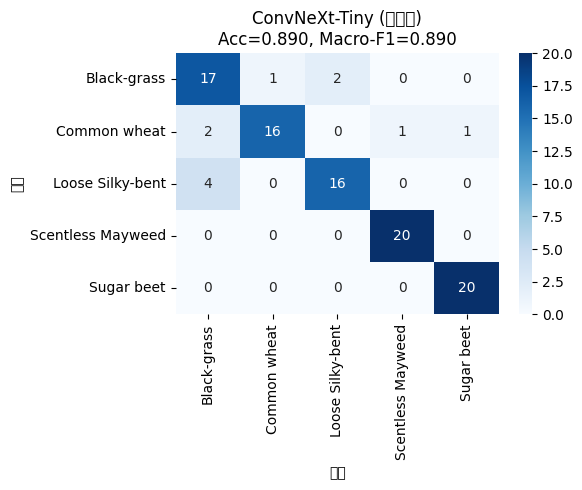

/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()



分类报告:
                   precision    recall  f1-score   support

      Black-grass     0.7391    0.8500    0.7907        20
     Common wheat     0.9412    0.8000    0.8649        20
 Loose Silky-bent     0.8889    0.8000    0.8421        20
Scentless Mayweed     0.9524    1.0000    0.9756        20
       Sugar beet     0.9524    1.0000    0.9756        20

         accuracy                         0.8900       100
        macro avg     0.8948    0.8900    0.8898       100
     weighted avg     0.8948    0.8900    0.8898       100



/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_19988/1996284089.py:20: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25439

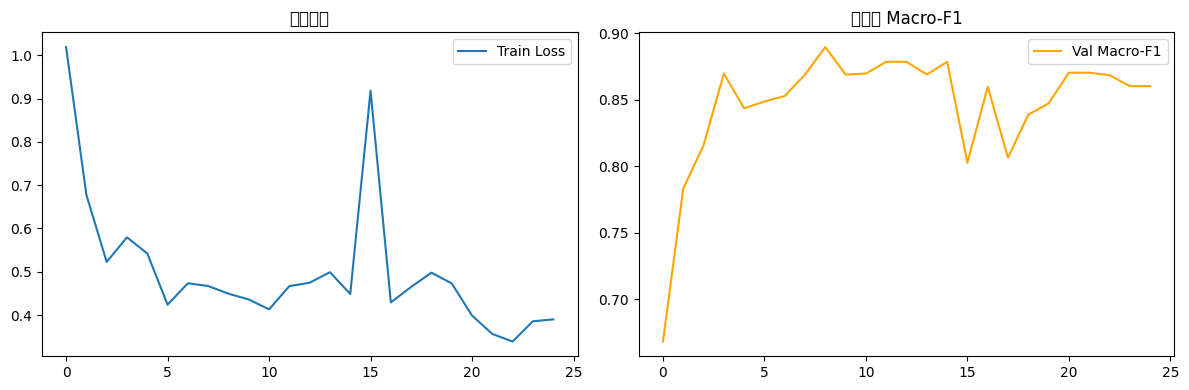

TTA Eval:   0%|          | 0/100 [00:00<?, ?it/s]

NameError: name 'predict_with_tta' is not defined

In [21]:
# 混淆矩阵 + 分类报告
cm = confusion_matrix(result['labels'], result['preds'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f"{result['name']}\nAcc={result['acc']:.3f}, Macro-F1={result['f1']:.3f}")
plt.xlabel('预测'); plt.ylabel('真实')
plt.tight_layout(); plt.show()

print("\n分类报告:")
print(classification_report(result['labels'], result['preds'],
                            target_names=classes, digits=4))

# 训练曲线
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result['history']['train_loss'], label='Train Loss')
axes[0].set_title('训练损失'); axes[0].legend()
axes[1].plot(result['history']['val_f1'], label='Val Macro-F1', color='orange')
axes[1].set_title('验证集 Macro-F1'); axes[1].legend()
plt.tight_layout(); plt.show()

# ---------- TTA 评估 ----------
@torch.no_grad()
def predict_one_image(model, img_pil, device, img_size=224):
    """对新图像：绿色分割 → TTA → 平均概率"""
    model.eval()
    img_pil = green_segment(img_pil)   # 现在返回的是 image，OK

    tta_transforms = [
        transforms.Compose([transforms.Resize(int(img_size*1.14)),
                            transforms.CenterCrop(img_size)]),
        transforms.Compose([transforms.Resize(int(img_size*1.14)),
                            transforms.CenterCrop(img_size),
                            transforms.RandomHorizontalFlip(p=1.0)]),
        transforms.Compose([transforms.Resize(int(img_size*1.14)),
                            transforms.CenterCrop(img_size),
                            transforms.RandomVerticalFlip(p=1.0)]),
    ]
    normalize = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    probs = []
    for t in tta_transforms:
        tensor = normalize(t(img_pil)).unsqueeze(0).to(device)
        logits = model(tensor)
        probs.append(F.softmax(logits, dim=1))
    return torch.mean(torch.stack(probs), dim=0)
# 在验证集上跑 TTA
model = result['model']
model.eval()
tta_preds, tta_labels = [], []
for i in tqdm(range(len(val_ds)), desc='TTA Eval'):
    img_path, label = val_ds.samples[i]
    img = Image.open(img_path).convert('RGB')
    probs = predict_with_tta(model, img, DEVICE)
    tta_preds.append(probs.argmax(1).item())
    tta_labels.append(label)

tta_acc = (np.array(tta_preds) == np.array(tta_labels)).mean()
tta_f1 = f1_score(tta_labels, tta_preds, average='macro', zero_division=0)
print(f"\nTTA 结果: val_acc={tta_acc:.4f}, macro_F1={tta_f1:.4f}")
print(f"相比无 TTA: acc {tta_acc - result['acc']:+.4f}, F1 {tta_f1 - result['f1']:+.4f}")

In [ ]:
import pandas as pd
import os
from PIL import Image

assert os.path.exists(TEST_DIR), f"TEST_DIR 不存在: {TEST_DIR}"
model = result['model']
model.eval()

test_images = sorted([f for f in os.listdir(TEST_DIR)
                      if f.lower().endswith(('.png','.jpg','.jpeg'))])
print(f"测试集图片数: {len(test_images)}")

all_preds = []
for fname in tqdm(test_images, desc='Predicting test'):
    img = Image.open(os.path.join(TEST_DIR, fname)).convert('RGB')
    probs = predict_one_image(model, img, DEVICE)
    all_preds.append(probs.argmax(1).item())

sub = pd.DataFrame({
    'image': test_images,
    'predicted_class': [classes[p] for p in all_preds]
})
sub.to_csv('submission_convnext_green_seg.csv', index=False)
print(sub['predicted_class'].value_counts())